# 04 - Conformal Prediction  *(the payoff)*

**Split conformal** wraps *any* model with a coverage guarantee and **no retraining**:

1. Hold out a calibration set the model never saw.
2. Compute the absolute errors on it.
3. Take the `ceil((n+1)*0.9)/n` empirical quantile of those errors as the half-width.

Under a mild **exchangeability** assumption this covers at the nominal rate - whatever the
model, whatever the data.

In [1]:
import sys
from pathlib import Path

_root = Path.cwd()
while not (_root / "pyproject.toml").exists() and _root != _root.parent:
    _root = _root.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.artifacts import save_fig, save_json

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
NOMINAL = 0.90
SEED = 42

## Split conformal hits nominal on every error structure

homoscedastic    coverage=0.923
heteroscedastic  coverage=0.901


skewed           coverage=0.887
heavy_tailed     coverage=0.907


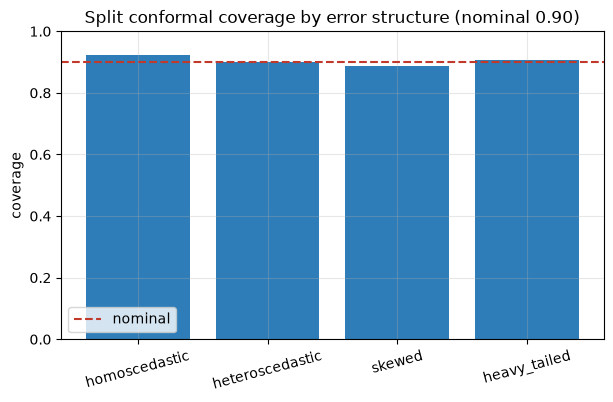

In [2]:
from src.datasets.synthetic import STRUCTURES, make_synthetic
from src.intervals.conformal import SplitConformal, AdaptiveConformal
from src.evaluation.coverage import coverage
from src.evaluation.conditional import conditional_coverage
from src.visualisation import plot_intervals, plot_conditional_coverage
from sklearn.ensemble import GradientBoostingRegressor

split_cov = {}
for s in STRUCTURES:
    d = make_synthetic(s, 6000, SEED)
    sc = SplitConformal(coverage=NOMINAL).fit(d.x[:4000], d.y[:4000])
    lo, hi = sc.predict_interval(d.x[4000:])
    split_cov[s] = float(coverage(d.y[4000:], lo, hi))
    print(f"{s:16s} coverage={split_cov[s]:.3f}")

fig, ax = plt.subplots()
ax.bar(list(split_cov), list(split_cov.values()), color="#2E7DB8")
ax.axhline(NOMINAL, color="#C0392B", ls="--", label="nominal")
ax.set_ylim(0, 1); ax.set_ylabel("coverage"); ax.legend()
plt.setp(ax.get_xticklabels(), rotation=15)
ax.set_title("Split conformal coverage by error structure (nominal 0.90)")
save_fig(fig, "04_split_conformal_coverage")
plt.show()

## Wrap a model you already trained - no retraining, same guarantee

In [3]:
d = make_synthetic("heteroscedastic", 6000, 7)
model = GradientBoostingRegressor(random_state=0).fit(d.x[:3000], d.y[:3000])
wrapped = SplitConformal(base_estimator=model, coverage=NOMINAL)
wrapped.fit(d.x[3000:4500], d.y[3000:4500], prefit=True)  # calibration only
lo, hi = wrapped.predict_interval(d.x[4500:])
wrap_cov = float(coverage(d.y[4500:], lo, hi))
print(f"Wrapped a pre-fit booster (no retraining). Coverage: {wrap_cov:.3f}; half-width q={wrapped._q:.2f}")
print(f"Same fitted object reused: {wrapped._model is model}")

Wrapped a pre-fit booster (no retraining). Coverage: 0.895; half-width q=8.15
Same fitted object reused: True


## Adaptive (Mondrian) conformal: let the width vary by region

Plain conformal's one weakness is a single constant width. Compute the conformal quantile
**separately within prediction regions** and the width varies while the guarantee holds.

Adaptive conformal coverage: 0.929


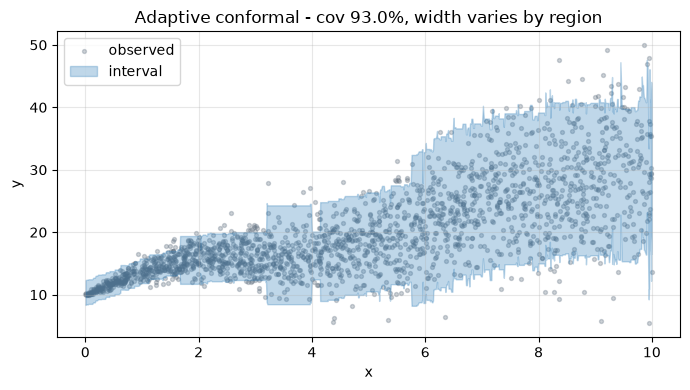

In [4]:
d = make_synthetic("heteroscedastic", 6000, SEED)
x_tr, y_tr, x_te, y_te = d.x[:4000], d.y[:4000], d.x[4000:], d.y[4000:]
ac = AdaptiveConformal(coverage=NOMINAL, n_bins=5, min_bin=50).fit(x_tr, y_tr)
lo, hi = ac.predict_interval(x_te)
ac_cov = float(coverage(y_te, lo, hi))
cond = conditional_coverage(y_te, lo, hi, by=x_te.ravel(), n_bins=8)
print(f"Adaptive conformal coverage: {ac_cov:.3f}")

fig = plot_intervals(x_te, y_te, lo, hi, title=f"Adaptive conformal - cov {ac_cov:.1%}, width varies by region")
save_fig(fig, "04_adaptive_band")
plt.show()

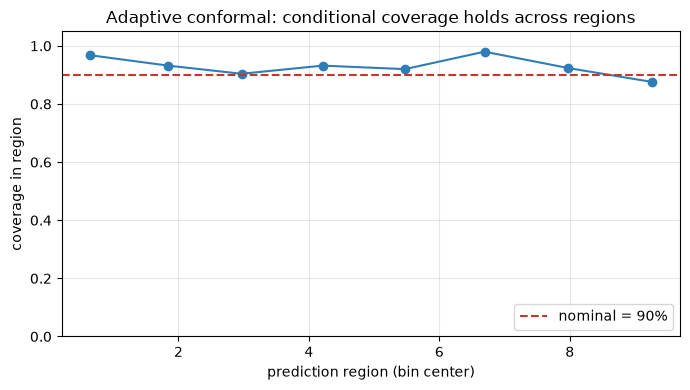

PosixPath('/workspaces/prediction_intervals_arena/outputs/data/04_conformal.json')

In [5]:
fig = plot_conditional_coverage(cond, nominal=NOMINAL)
fig.axes[0].set_title("Adaptive conformal: conditional coverage holds across regions")
save_fig(fig, "04_adaptive_conditional")
plt.show()

save_json("04_conformal", {
    "nominal_coverage": NOMINAL,
    "split_conformal_coverage_by_structure": split_cov,
    "wrapped_prefit_coverage": wrap_cov,
    "adaptive_conformal_coverage": ac_cov,
    "adaptive_conditional": cond.to_dict(orient="records"),
})

**The guarantee, plainly:** split conformal covers at the nominal rate as long as the
calibration and test points are exchangeable. Where that breaks - distribution shift,
time series - the guarantee weakens (see `forecasting_arena`). Everywhere else, it is a
few lines of code and it just works.